# Assignment: Fractional Knapsack (Greedy)

In [9]:
def fractional_knapsack(weights, values, capacity):
    items = sorted(
        zip(weights, values),
        key=lambda item: item[1] / item[0],
        reverse=True
    )
    print("Sorted by value/weight:", [(w, v, round(v / w, 2)) for w, v in items])

    total_value = 0
    for weight, value in items:
        if capacity <= 0:
            break
        take = min(weight, capacity)
        total_value += take * value / weight
        print(f"Taking {take} of item with weight {weight} and value {value}")
        capacity -= take

    return total_value


weights = [10, 40, 30]
values = [60, 100, 120]
capacity = 50

print("Weights:", weights)
print("Values:", values)
print("Capacity:", capacity)
print("Maximum Value:", fractional_knapsack(weights, values, capacity))

print("\nTime and Space Complexity")
print("Time : O(n log n)  [sorting by value/weight]")
print("Space : O(n)")

Weights: [10, 40, 30]
Values: [60, 100, 120]
Capacity: 50
Sorted by value/weight: [(10, 60, 6.0), (30, 120, 4.0), (40, 100, 2.5)]
Taking 10 of item with weight 10 and value 60
Taking 30 of item with weight 30 and value 120
Taking 10 of item with weight 40 and value 100
Maximum Value: 205.0

Time and Space Complexity
Time : O(n log n)  [sorting by value/weight]
Space : O(n)


# Analysis: Time and Memory Comparison

Items	Time (s)		Peak Memory (KB)
10	0.00000180		0.508
20	0.00000310		0.570
30	0.00000440		0.633
40	0.00000560		0.695
50	0.00000690		0.789
60	0.00000920		0.883
70	0.00000990		0.977
80	0.00001130		1.102
90	0.00001280		1.102
100	0.00001370		1.250
110	0.00001570		1.641
120	0.00001750		1.875
130	0.00001840		3.281
140	0.00001990		3.594
150	0.00002120		4.094
160	0.00002240		4.406
170	0.00003280		4.719
180	0.00002540		5.250
190	0.00002700		5.562
200	0.00002820		5.875
210	0.00003000		6.438
220	0.00003200		6.750
230	0.00003310		7.062
240	0.00003440		7.656
250	0.00003685		7.969
260	0.00003670		8.281
270	0.00004035		10.984
280	0.00004140		11.375
290	0.00004300		11.719
300	0.00004310		12.125


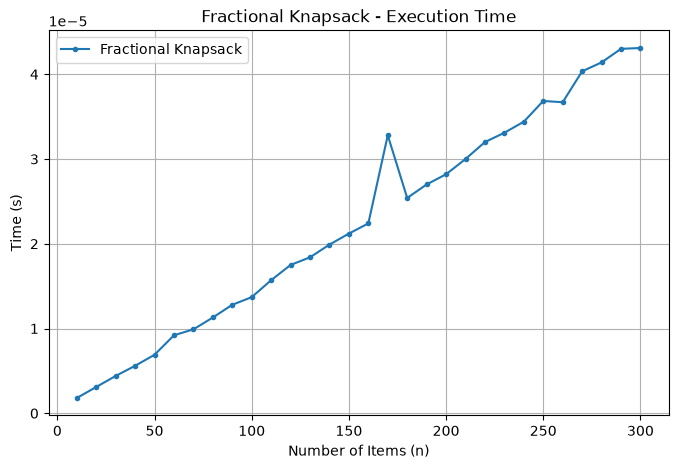

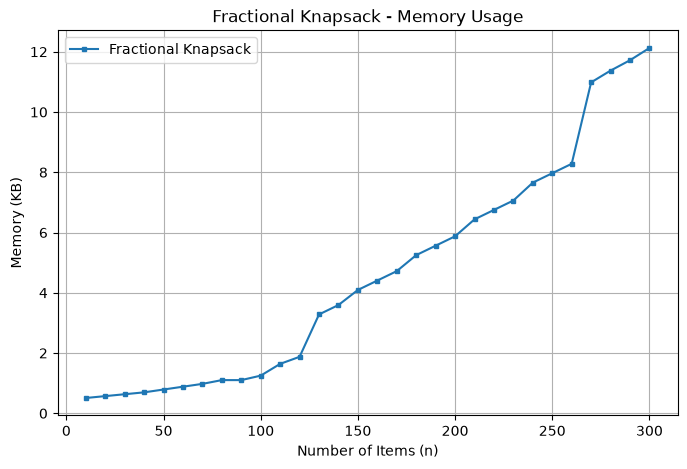

In [3]:
import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


def measure_time(function, *args, repeats=1000):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(*args)
        times.append(perf_counter() - start)
    return statistics.median(times)


def measure_memory(function, *args, repeats=3):
    memory_values = []
    for _ in range(repeats):
        tracemalloc.start()
        function(*args)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memory_values.append(peak / 1024)
    return statistics.median(memory_values)


all_weights = [(i % 20) + 1 for i in range(1, 301)]
all_values = [((i * 7) % 100) + 10 for i in range(1, 301)]
sizes = list(range(10, 301, 10))

execution_times = []
peak_memory = []

for n in sizes:
    test_weights = all_weights[:n]
    test_values = all_values[:n]
    test_capacity = sum(test_weights) // 2

    execution_times.append(
        measure_time(fractional_knapsack, test_weights, test_values, test_capacity)
    )
    peak_memory.append(
        measure_memory(fractional_knapsack, test_weights, test_values, test_capacity)
    )


print("Items\tTime (s)\t\tPeak Memory (KB)")
for n, t, m in zip(sizes, execution_times, peak_memory):
    print(f"{n}\t{t:.8f}\t\t{m:.3f}")


plt.figure(figsize=(8, 5))
plt.plot(sizes, execution_times, marker='o', markersize=3, label="Fractional Knapsack")
plt.xlabel("Number of Items (n)")
plt.ylabel("Time (s)")
plt.title("Fractional Knapsack - Execution Time")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(sizes, peak_memory, marker='s', markersize=3, label="Fractional Knapsack")
plt.xlabel("Number of Items (n)")
plt.ylabel("Memory (KB)")
plt.title("Fractional Knapsack - Memory Usage")
plt.legend()
plt.grid(True)
plt.show()